# Análise exploratória · Vitaliza · Grupo 2

**Pergunta desta etapa:** quem saiu entre 01/07 e 30/09/2026 se comportava diferente de quem ficou?

É a continuação da limpeza (`src/normaliza_datas.py`): partimos dos arquivos já processados e seguimos o roteiro da aula 2 em sete passos. Em cada passo, escrevemos **o que decidimos e por quê** antes do código, e conferimos o resultado depois dele.

**Regras que seguimos** (do `AGENTS.md` do grupo):
- nada em `dados/brutos/` é alterado; tabelas intermediárias vão para `dados/processados/`;
- nenhuma variável usa informação de depois de 30/06/2026, o último dia antes da janela de saída;
- mostramos as linhas antes e depois de cada junção;
- toda decisão vai para o `decisoes.md`.

**Arquivos usados:** `eventos_assinatura` e `assinaturas` (processados), `atividades.parquet`, `uso_mensal.csv`, `usuarios.csv` e `tickets_suporte.csv`. Os textos livres (questionário de entrada e mensagens ao suporte) ficam para a aula 5, quando texto vira variável.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRUTOS = RAIZ / "dados" / "brutos"
PROC = RAIZ / "dados" / "processados"
FIGS = RAIZ / "saidas" / "eda"
FIGS.mkdir(parents=True, exist_ok=True)

INICIO_JANELA = pd.Timestamp("2026-07-01")   # 01/07/2026 00:00, horário de Brasília
FIM_JANELA = pd.Timestamp("2026-10-01")      # até 30/09/2026 23:59
INICIO_USO = pd.Timestamp("2026-04-01")      # uso medido em abril, maio e junho
COR_SAIU, COR_FICOU = "#d6453d", "#9a948a"

## Passo 1 · Definir os grupos

**O que decidimos.** A base é quem **pagava em 30/06/2026**: tem algum evento pago (com plano preenchido) até essa data e nenhuma `assinatura_expirada` até ela. Na limpeza, já tínhamos definido que churn é o fim do período pago, não o clique em cancelar.

**Como conferimos.** Antes de usar a regra em 30/06, aplicamos a mesma função em três datas para as quais o enunciado traz o número oficial.

In [2]:
eventos = pd.read_csv(PROC / "eventos_assinatura.csv", parse_dates=["data_hora_brt"])
assinaturas = pd.read_csv(PROC / "assinaturas.csv", parse_dates=["inicio", "data_fim"])
print(f"eventos: {len(eventos):,} linhas | assinaturas: {len(assinaturas):,} linhas")

def pagantes_ativos(ultimo_dia):
    """Pagava no fim de `ultimo_dia`: tem evento pago (plano preenchido) até o dia
    e nenhuma assinatura_expirada até o dia."""
    limite = pd.Timestamp(ultimo_dia) + pd.Timedelta(days=1)
    ate = eventos[eventos["data_hora_brt"] < limite]
    pagou = set(ate.loc[ate["plano"].notna(), "user_id"])
    expirou = set(ate.loc[ate["evento"] == "assinatura_expirada", "user_id"])
    return pagou - expirou

conferencia = pd.DataFrame(
    [("31/03/2026", "ativos no início de abril", 14_237),
     ("31/08/2026", "ativos no início de setembro", 14_319),
     ("30/09/2026", "pagantes ativos no corte", 14_753)],
    columns=["data", "o que o enunciado informa", "enunciado"])
conferencia["nossa regra"] = [len(pagantes_ativos(pd.to_datetime(d, dayfirst=True))) for d in conferencia["data"]]
conferencia["diferença"] = conferencia["nossa regra"] - conferencia["enunciado"]
conferencia

eventos: 275,565 linhas | assinaturas: 32,583 linhas


,data,o que o enunciado informa,enunciado,nossa regra,diferença
0,31/03/2026,ativos no início de abril,14237,14237,0
1,31/08/2026,ativos no início de setembro,14319,14319,0
2,30/09/2026,pagantes ativos no corte,14753,14753,0


A regra reproduz os três números **exatamente**.

O roteiro da aula sugeria contar também `reembolso` e `chargeback` como fim. Testamos essa versão, e ela erra por 3 e por 4. O motivo está nos dados: todo reembolso é seguido de expiração no mesmo dia, mas **4 chargebacks não encerraram a assinatura**. As contas continuam ativas no corte. Por isso ficamos só com `assinatura_expirada`, que também responde a uma dúvida que tínhamos deixado em aberto na limpeza.

In [3]:
def pagantes_ativos_prof(ultimo_dia):
    limite = pd.Timestamp(ultimo_dia) + pd.Timedelta(days=1)
    ate = eventos[eventos["data_hora_brt"] < limite]
    pagou = set(ate.loc[ate["plano"].notna(), "user_id"])
    saiu = set(ate.loc[ate["evento"].isin(["assinatura_expirada", "reembolso", "chargeback"]), "user_id"])
    return pagou - saiu

alt = conferencia[["data", "enunciado"]].copy()
alt["fim = expirada, reembolso ou chargeback"] = [len(pagantes_ativos_prof(pd.to_datetime(d, dayfirst=True))) for d in alt["data"]]

fins = (eventos[eventos["evento"].isin(["reembolso", "chargeback", "assinatura_expirada"])]
        .pivot_table(index="user_id", columns="evento", values="data_hora_brt", aggfunc="min"))
for ev in ["reembolso", "chargeback"]:
    com = fins[ev].notna()
    sem_exp = (com & fins["assinatura_expirada"].isna()).sum()
    dias = ((fins.loc[com, "assinatura_expirada"] - fins.loc[com, ev]).dt.total_seconds() / 86400).dropna()
    print(f"{ev}: {com.sum()} contas | sem expiração depois: {sem_exp} | "
          f"dias até expirar (mediana): {dias.median():.2f}")
alt

reembolso: 72 contas | sem expiração depois: 0 | dias até expirar (mediana): -0.05
chargeback: 296 contas | sem expiração depois: 4 | dias até expirar (mediana): 0.02


,data,enunciado,"fim = expirada, reembolso ou chargeback"
0,31/03/2026,14237,14237
1,31/08/2026,14319,14316
2,30/09/2026,14753,14749


Com a regra validada, separamos os grupos: **saiu** é quem teve `assinatura_expirada` entre 01/07 e 30/09/2026; **ficou** é o resto da base.

In [4]:
base = sorted(pagantes_ativos("2026-06-30"))
janela = eventos[(eventos["data_hora_brt"] >= INICIO_JANELA) & (eventos["data_hora_brt"] < FIM_JANELA)]
saidas_janela = set(janela.loc[janela["evento"] == "assinatura_expirada", "user_id"])

grupos = pd.DataFrame({"user_id": base})
grupos["saiu"] = grupos["user_id"].isin(saidas_janela).astype(int)
grupos.to_csv(PROC / "grupos.csv", index=False)

print(f"base (pagava em 30/06/2026): {len(grupos):,}")
print(f"saiu entre 01/07 e 30/09:    {grupos['saiu'].sum():,}")
print(f"ficou:                       {(grupos['saiu'] == 0).sum():,}")
print(f"taxa de saída no trimestre:  {grupos['saiu'].mean():.1%}")
print(f"três meses de churn a 6,6%:  {1 - (1 - 0.066) ** 3:.1%}  (referência do enunciado)")

base (pagava em 30/06/2026): 14,059
saiu entre 01/07 e 30/09:    2,343
ficou:                       11,716
taxa de saída no trimestre:  16.7%
três meses de churn a 6,6%:  18.5%  (referência do enunciado)


A taxa do trimestre (16,7%) fica perto de três meses de churn a 6,6% ao mês (18,5%). É um pouco menor porque julho, agosto e setembro foram meses abaixo da média de 2026, como diz o enunciado.

## Passo 2 · Conferir a qualidade dos arquivos novos

Para medir o uso, havia duas fontes: o `uso_mensal.csv`, a tabela do BI, e o `atividades.parquet`, um treino por linha. Antes de escolher, comparamos as duas no mesmo período.

In [5]:
uso = pd.read_csv(BRUTOS / "uso_mensal.csv")
ativ = pd.read_parquet(BRUTOS / "atividades.parquet")
ativ["inicio"] = pd.to_datetime(ativ["inicio"])
print(f"uso_mensal: {len(uso):,} linhas | atividades: {len(ativ):,} linhas")

ativ["mes"] = ativ["inicio"].dt.strftime("%Y-%m")
comp = []
for mes in ["2026-04", "2026-05", "2026-06"]:
    a_mes = ativ[ativ["mes"] == mes]
    comp.append({"mês": mes,
                 "uso_mensal (soma de atividades)": uso.loc[uso["mes"] == mes, "atividades"].sum(),
                 "atividades.parquet (todos)": len(a_mes),
                 "atividades.parquet (só origem app)": (a_mes["origem"] == "app").sum()})
pd.DataFrame(comp)

uso_mensal: 591,662 linhas | atividades: 1,254,475 linhas


,mês,uso_mensal (soma de atividades),atividades.parquet (todos),atividades.parquet (só origem app)
0,2026-04,98789,143311,100561
1,2026-05,100371,146061,101801
2,2026-06,87383,126504,88884


**Achado 1.** O `uso_mensal` soma quase exatamente os treinos com origem `app`. Ele **não conta os treinos sincronizados do Garmin e do Apple Health**, cerca de 30% do total. Como quatro em cada dez contas têm relógio, usar o `uso_mensal` faria quem treina com relógio parecer menos ativo do que é. **Decisão:** medir os treinos pelo `atividades.parquet` e usar o `uso_mensal` só para as aberturas do app (`sessoes_app`), que não dependem do relógio.

O dicionário diz que o horário do treino vem "como veio da origem". Olhamos a hora mais comum por origem:

In [6]:
ativ["hora"] = ativ["inicio"].dt.hour
pico = (ativ.groupby("origem")["hora"].agg(lambda h: h.value_counts().idxmax())
        .rename("hora mais comum").to_frame())
pico["treinos antes das 5h"] = ativ.groupby("origem")["hora"].apply(lambda h: (h < 5).sum())
pico

,hora mais comum,treinos antes das 5h
origem,,
app,6,3
apple_health,6,0
garmin,9,5828


**Achado 2.** Os treinos do Garmin têm o pico às 9h e milhares de registros antes das 5h; app e Apple Health têm o pico às 6h. O Garmin grava em **UTC**, três horas à frente de Brasília, o mesmo padrão das lojas no log de assinaturas. **Decisão:** subtrair 3 horas dos treinos do Garmin, o que importa para contar dias sem treino na virada do dia.

Também olhamos os tipos de treino antes e depois de uma data:

In [7]:
pd.crosstab(ativ["tipo"], ativ["inicio"] >= pd.Timestamp("2026-04-15"),
            colnames=["a partir de 15/04/2026"])

a partir de 15/04/2026,False,True
tipo,,
caminhada,78559,39465
corrida,153624,70194
forca,75646,37058
funcional,97442,48034
hiit,0,109934
pedal,36564,17176
ride,0,40765
run,0,162108
strength,0,85548


**Achado 3.** A partir de 15/04/2026 aparecem `run`, `walk`, `ride` e `strength` ao lado de `corrida`, `caminhada`, `pedal` e `forca`, e surge o tipo `hiit`. Parece uma versão nova do app gravando os nomes em inglês. **Decisão:** traduzir os quatro nomes para português, para não partir o "ao ar livre" em dois. O `hiit` fica como tipo próprio.

In [8]:
TIPOS = {"run": "corrida", "walk": "caminhada", "ride": "pedal", "strength": "forca"}
AR_LIVRE = {"corrida", "caminhada", "pedal"}

ativ["inicio_brt"] = ativ["inicio"].where(ativ["origem"] != "garmin",
                                          ativ["inicio"] - pd.Timedelta(hours=3))
ativ["tipo_pt"] = ativ["tipo"].replace(TIPOS)
ativ["ar_livre"] = ativ["tipo_pt"].isin(AR_LIVRE)
print("treinos do Garmin deslocados em −3h:", (ativ["origem"] == "garmin").sum())
print("tipos depois da padronização:", sorted(ativ["tipo_pt"].unique()))
print("duração zero:", (ativ["duracao_min"] == 0).sum(), "| acima de 4h:", (ativ["duracao_min"] > 240).sum())

treinos do Garmin deslocados em −3h: 207954
tipos depois da padronização: ['caminhada', 'corrida', 'forca', 'funcional', 'hiit', 'pedal', 'yoga']
duração zero: 3649 | acima de 4h: 1597


Treinos com duração zero ou acima de 4 horas existem, mas são poucos e não mudam medianas. Ficam como estão, apenas registrados.

No cadastro e no suporte, conferimos unicidade e valores:

In [9]:
usuarios = pd.read_csv(PROC / "usuarios.csv", keep_default_na=False, na_values={"idade": [""]})
tickets = pd.read_csv(BRUTOS / "tickets_suporte.csv", parse_dates=["aberto_em"])
print("usuarios (processado):", len(usuarios), "linhas |", usuarios["user_id"].nunique(), "user_id distintos")
print("sexo no bruto (texto livre):", usuarios["sexo_original"].value_counts().to_dict())
print("nascimento impossível tratado como faltante:", int(usuarios["nascimento_invalido"].sum()),
      "| idade disponível:", int(usuarios["idade"].notna().sum()))
print("relógio:", usuarios["relogio_conectado"].value_counts().to_dict())
print("canal de aquisição:", usuarios["canal_aquisicao"].value_counts().to_dict())
print("tickets:", len(tickets), "| categorias:", tickets["categoria_atendente"].value_counts().to_dict())

usuarios (processado): 64888 linhas | 64888 user_id distintos
sexo no bruto (texto livre): {'F': 19310, 'M': 17635, 'Fem': 6646, 'feminino': 6513, 'Masc': 5833, 'masculino': 5811, '': 3140}
nascimento impossível tratado como faltante: 606 | idade disponível: 60984
relógio: {'nenhum': 40120, 'garmin': 13389, 'apple_watch': 11379}
canal de aquisição: {'organico': 18531, 'influenciador': 14067, 'meta_ads': 11939, 'indicacao': 8117, 'google_ads': 6801, 'parceria_corporativa': 5433}
tickets: 4422 | categorias: {'tecnico': 961, 'cancelamento': 913, 'conta': 757, 'cobranca': 651, 'conteudo': 588, 'duvida_geral': 552}


O campo `sexo` tinha sete grafias para dois valores, e 606 datas de nascimento eram impossíveis (datas padrão do sistema, como 1900-01-01). Os dois casos foram tratados na limpeza (`src/normaliza_datas.py`), e aqui já usamos o cadastro processado.

**Resumo da qualidade pelas cinco dimensões vistas em aula:** completude, validade, consistência, unicidade e temporalidade.

In [10]:
uso_dup = uso.duplicated(["user_id", "mes"]).sum()
ativ_dup = ativ["atividade_id"].duplicated().sum()
dim = pd.DataFrame([
    ("Completude", "células vazias nas colunas que a análise usa",
     f"usuarios: nascimento vazio {(usuarios['data_nascimento'] == '').sum():,}, sexo vazio {(usuarios['sexo'] == '').sum():,}; "
     f"atividades: distância vazia em {ativ['distancia_km'].isna().mean():.0%} (treinos sem GPS, esperado); uso_mensal e tickets sem vazios críticos"),
    ("Validade", "valores dentro do domínio possível",
     f"{int(usuarios['nascimento_invalido'].sum())} nascimentos impossíveis (1900-01-01 e 2031-05-12) → faltante; "
     f"{(ativ['duracao_min'] == 0).sum():,} treinos com duração 0 e {(ativ['duracao_min'] > 240).sum():,} acima de 4h → mantidos e registrados"),
    ("Consistência", "a mesma informação bate entre arquivos e grafias",
     "uso_mensal soma só os treinos do app (ignora relógio); tipos em inglês e português desde 15/04; sexo com sete grafias; "
     "data_fim do retrato bate 100% com assinatura_expirada do log"),
    ("Unicidade", "chaves sem repetição",
     f"user_id único em usuarios; atividade_id repetido: {ativ_dup}; user_id+mês repetido no uso_mensal: {uso_dup}; "
     f"uma linha por user_id na tabela final (conferido na junção)"),
    ("Temporalidade", "período coberto e fuso de cada data",
     "eventos desde 07/2024, atividades jan–set/2026, uso_mensal jan/2025–set/2026, tickets desde 07/2025; "
     "lojas e Garmin em UTC → convertidos para Brasília; nada usado depois de 30/06 nas variáveis"),
], columns=["dimensão", "o que conferimos", "resultado"])
with pd.option_context("display.max_colwidth", None):
    display(dim.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

dimensão,o que conferimos,resultado
Completude,células vazias nas colunas que a análise usa,"usuarios: nascimento vazio 3,298, sexo vazio 3,140; atividades: distância vazia em 46% (treinos sem GPS, esperado); uso_mensal e tickets sem vazios críticos"
Validade,valores dentro do domínio possível,"606 nascimentos impossíveis (1900-01-01 e 2031-05-12) → faltante; 3,649 treinos com duração 0 e 1,597 acima de 4h → mantidos e registrados"
Consistência,a mesma informação bate entre arquivos e grafias,uso_mensal soma só os treinos do app (ignora relógio); tipos em inglês e português desde 15/04; sexo com sete grafias; data_fim do retrato bate 100% com assinatura_expirada do log
Unicidade,chaves sem repetição,user_id único em usuarios; atividade_id repetido: 0; user_id+mês repetido no uso_mensal: 0; uma linha por user_id na tabela final (conferido na junção)
Temporalidade,período coberto e fuso de cada data,"eventos desde 07/2024, atividades jan–set/2026, uso_mensal jan/2025–set/2026, tickets desde 07/2025; lojas e Garmin em UTC → convertidos para Brasília; nada usado depois de 30/06 nas variáveis"


`user_id` é único no cadastro, então a junção com ele não multiplica linhas.

## Passo 3 · Uma linha por assinante, tudo medido antes de 01/07

**O que decidimos.** Cada variável descreve o assinante **até 30/06/2026**. O que aconteceu depois é justamente o que queremos explicar, e usá-lo seria vazamento.

- **Plano e canal em 30/06** vêm do último evento pago no log, **não** do `assinaturas.csv`, que é um retrato de 01/10 e pode ter mudado depois. Conferimos: nesta base, nenhum plano mudou entre 30/06 e 01/10.
- **Renovação desligada:** o último evento de intenção até 30/06 foi desligar a renovação ou cancelar pelo site.
- **Tempo de casa:** dias entre a primeira cobrança e 30/06.

In [11]:
antes = eventos[eventos["data_hora_brt"] < INICIO_JANELA]

ultimo_pago = (antes[antes["plano"].notna()].sort_values("data_hora_brt")
               .groupby("user_id").last()[["plano", "canal_cobranca"]]
               .rename(columns={"plano": "plano_30jun", "canal_cobranca": "canal_30jun"}))

INTENCAO = {"renovacao_automatica_desligada", "cancelamento_web", "renovacao_automatica_religada"}
ultima_intencao = (antes[antes["evento"].isin(INTENCAO)].sort_values("data_hora_brt")
                   .groupby("user_id")["evento"].last())
renov_desligada = ultima_intencao.isin({"renovacao_automatica_desligada", "cancelamento_web"}).rename("renovacao_desligada")

carencia = (antes[(antes["evento"] == "periodo_carencia") & (antes["data_hora_brt"] >= INICIO_USO)]
            .groupby("user_id").size().gt(0).rename("carencia_abr_jun"))

tempo_casa = assinaturas.set_index("user_id")["inicio"].rsub(pd.Timestamp("2026-06-30")).dt.days.rename("tempo_casa_dias")

# divergência retrato × histórico: o plano mudou depois de 30/06?
chk = ultimo_pago.join(assinaturas.set_index("user_id")["plano_atual"], how="inner")
print("plano em 30/06 diferente do plano no retrato de 01/10:", (chk["plano_30jun"] != chk["plano_atual"]).sum())

plano em 30/06 diferente do plano no retrato de 01/10: 0


**Uso em abril, maio e junho** (13 semanas), pelo `atividades.parquet` já corrigido: treinos e minutos por semana, % de treinos ao ar livre, tendência (treinos em junho menos treinos em abril) e dias sem treinar em 30/06. Do `uso_mensal`, só as aberturas do app.

In [12]:
jan = ativ[(ativ["inicio_brt"] >= INICIO_USO) & (ativ["inicio_brt"] < INICIO_JANELA)]
SEMANAS = 13  # 01/04 a 30/06

uso_ass = jan.groupby("user_id").agg(
    treinos=("atividade_id", "size"),
    minutos=("duracao_min", "sum"),
    ar_livre=("ar_livre", "sum"))
uso_ass["treinos_semana"] = uso_ass["treinos"] / SEMANAS
uso_ass["minutos_semana"] = uso_ass["minutos"] / SEMANAS
uso_ass["pct_ar_livre"] = uso_ass["ar_livre"] / uso_ass["treinos"]

por_mes = jan.assign(m=jan["inicio_brt"].dt.month).pivot_table(index="user_id", columns="m", values="atividade_id", aggfunc="size", fill_value=0)
uso_ass["tendencia_jun_abr"] = por_mes.get(6, 0) - por_mes.get(4, 0)

ultimo_treino = ativ[ativ["inicio_brt"] < INICIO_JANELA].groupby("user_id")["inicio_brt"].max()
dias_sem = (INICIO_JANELA - ultimo_treino).dt.days.rename("dias_sem_treino")

sessoes = (uso[uso["mes"].isin(["2026-04", "2026-05", "2026-06"])]
           .groupby("user_id")["sessoes_app"].mean().rename("sessoes_app_mes"))

**Perfil e suporte:** canal de aquisição e relógio conectado, do cadastro; chamados ao suporte abertos antes de 01/07.

In [13]:
perfil = usuarios.set_index("user_id")[["canal_aquisicao", "relogio_conectado", "idade", "faixa_etaria"]].copy()
perfil["tem_relogio"] = perfil["relogio_conectado"].ne("nenhum")
perfil["faixa_etaria"] = perfil["faixa_etaria"].replace("", "sem idade")

t_antes = tickets[tickets["aberto_em"] < INICIO_JANELA]
sup = t_antes.groupby("user_id").agg(chamados=("ticket_id", "size"))
sup["chamado_cobranca"] = t_antes[t_antes["categoria_atendente"] == "cobranca"].groupby("user_id").size().gt(0)

Juntamos tudo à base, uma parte por vez, conferindo que **nenhuma junção multiplica linhas**. "Sem dado" é quantos assinantes não aparecem naquela parte. Para cada caso, decidimos o que a ausência significa: sem treino no período vira 0 treino; sem evento de intenção vira renovação ligada; sem chamado vira 0 chamado. Quem não treinou nenhuma vez em 2026 fica com 181 dias sem treino (desde 01/01) e é marcado em `sem_treino_2026`.

In [14]:
tab = grupos.set_index("user_id")
passos = [("grupos (base em 30/06)", None)]
for nome, parte in [("plano e canal em 30/06", ultimo_pago), ("renovação desligada", renov_desligada.to_frame()),
                    ("carência abr–jun", carencia.to_frame()), ("tempo de casa", tempo_casa.to_frame()),
                    ("uso abr–jun (treinos)", uso_ass[["treinos_semana", "minutos_semana", "pct_ar_livre", "tendencia_jun_abr"]]),
                    ("dias sem treino", dias_sem.to_frame()), ("sessões no app", sessoes.to_frame()),
                    ("perfil (cadastro)", perfil[["canal_aquisicao", "tem_relogio", "idade", "faixa_etaria"]]), ("suporte", sup)]:
    antes_n = len(tab)
    tab = tab.join(parte, how="left")
    passos.append((nome, parte))
    assert len(tab) == antes_n, f"a junção com {nome} multiplicou linhas"
    print(f"{nome:<26} linhas: {antes_n:,} → {len(tab):,} | sem dado: {tab[parte.columns[0]].isna().sum():,}")

# preencher o que a ausência significa
tab["renovacao_desligada"] = tab["renovacao_desligada"].fillna(False).astype(bool)
tab["carencia_abr_jun"] = tab["carencia_abr_jun"].fillna(False).astype(bool)
tab[["treinos_semana", "minutos_semana", "tendencia_jun_abr"]] = tab[["treinos_semana", "minutos_semana", "tendencia_jun_abr"]].fillna(0)
tab["sem_treino_2026"] = tab["dias_sem_treino"].isna()
tab["dias_sem_treino"] = tab["dias_sem_treino"].fillna((INICIO_JANELA - pd.Timestamp("2026-01-01")).days)
tab["chamados"] = tab["chamados"].fillna(0).astype(int)
tab["chamado_cobranca"] = tab["chamado_cobranca"].fillna(False).astype(bool)
tab["sessoes_app_mes"] = tab["sessoes_app_mes"].fillna(0)

tab.reset_index().to_csv(PROC / "assinantes_30jun.csv", index=False)
print(f"\nassinantes_30jun.csv: {len(tab):,} linhas, uma por user_id ({tab.index.is_unique})")

plano e canal em 30/06     linhas: 14,059 → 14,059 | sem dado: 0
renovação desligada        linhas: 14,059 → 14,059 | sem dado: 11,005
carência abr–jun           linhas: 14,059 → 14,059 | sem dado: 14,044
tempo de casa              linhas: 14,059 → 14,059 | sem dado: 0
uso abr–jun (treinos)      linhas: 14,059 → 14,059 | sem dado: 746
dias sem treino            linhas: 14,059 → 14,059 | sem dado: 336
sessões no app             linhas: 14,059 → 14,059 | sem dado: 10
perfil (cadastro)          linhas: 14,059 → 14,059 | sem dado: 0
suporte                    linhas: 14,059 → 14,059 | sem dado: 12,215

assinantes_30jun.csv: 14,059 linhas, uma por user_id (True)


## Passo 4 · Descrever cada variável

Antes de comparar grupos, olhamos posição, dispersão e forma. A coluna "média ÷ mediana" mostra onde a média engana.

In [15]:
NUM = ["treinos_semana", "minutos_semana", "dias_sem_treino", "pct_ar_livre",
       "tendencia_jun_abr", "sessoes_app_mes", "tempo_casa_dias", "chamados"]
desc = tab[NUM].describe(percentiles=[.25, .5, .75]).T
desc["média ÷ mediana"] = desc["mean"] / desc["50%"].replace(0, np.nan)
desc[["count", "mean", "50%", "25%", "75%", "std", "min", "max", "média ÷ mediana"]]

,count,mean,50%,25%,75%,std,min,max,média ÷ mediana
treinos_semana,"14,059.00",2.01,1.85,0.92,2.77,1.48,0.00,12.46,1.09
minutos_semana,"14,059.00",93.03,81.28,40.96,127.66,74.47,0.00,757.36,1.14
dias_sem_treino,"14,059.00",15.59,3.00,1.00,9.00,35.97,0.00,181.00,5.20
pct_ar_livre,"13,313.00",0.55,0.73,0.17,0.83,0.34,0.00,1.00,0.76
tendencia_jun_abr,"14,059.00",-0.06,0.00,-4.00,3.00,7.00,-50.00,51.00,NaN
sessoes_app_mes,"14,059.00",8.76,6.67,3.00,12.67,7.28,0.00,66.67,1.31
tempo_casa_dias,"14,059.00",409.73,264.00,122.00,516.00,455.80,0.00,"2,121.00",1.55
chamados,"14,059.00",0.15,0.00,0.00,0.00,0.40,0.00,4.00,NaN


Em **dias sem treino**, a média (15,6) é cinco vezes a mediana (3). Metade da base treinou nos últimos três dias, e uma cauda longa de assinantes parados puxa a média. Por isso, nas comparações a seguir, usamos **mediana e quartis**, não média.

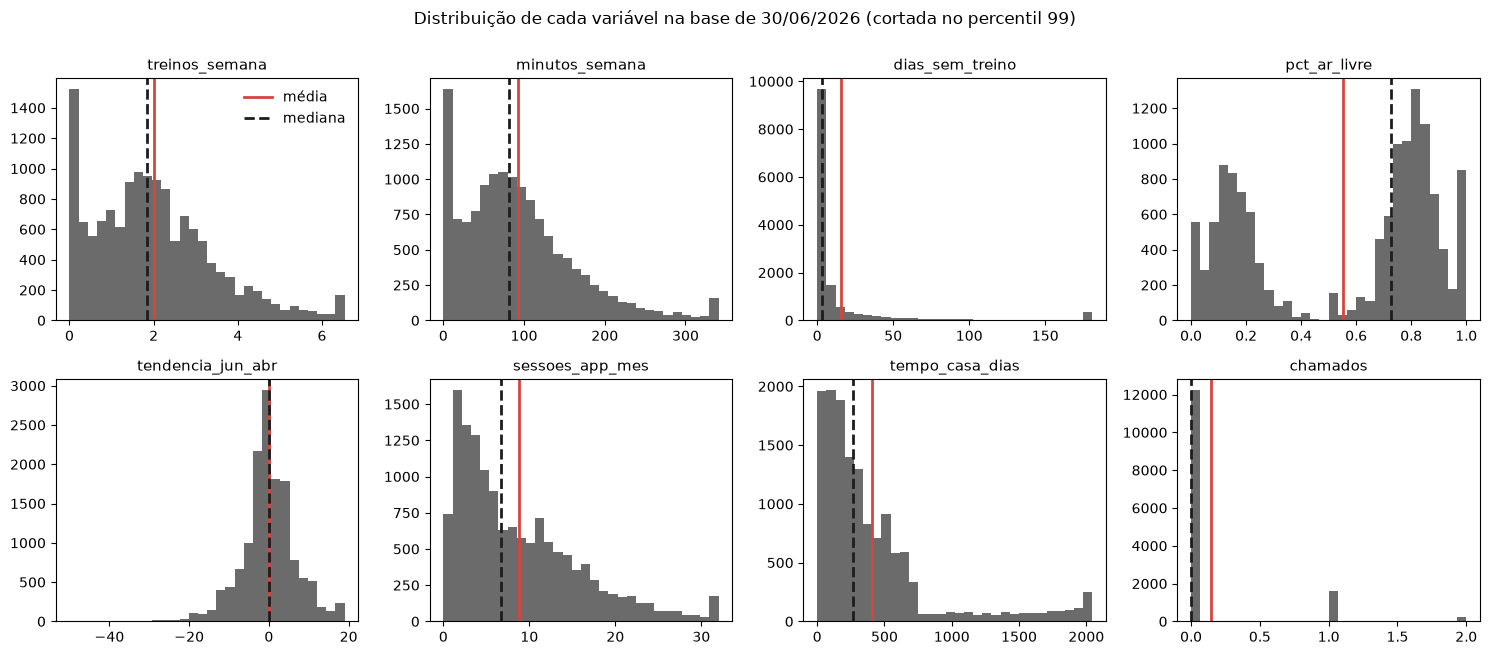

In [16]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axs.flat, NUM):
    v = tab[c].dropna()
    ax.hist(v.clip(upper=v.quantile(.99)), bins=30, color="#6b6b6b")
    ax.axvline(v.mean(), color=COR_SAIU, lw=2, label="média")
    ax.axvline(v.median(), color="#1d1d1f", lw=2, ls="--", label="mediana")
    ax.set_title(c, fontsize=11)
axs.flat[0].legend(frameon=False)
fig.suptitle("Distribuição de cada variável na base de 30/06/2026 (cortada no percentil 99)", y=1.0)
fig.tight_layout(); fig.savefig(FIGS / "01_distribuicoes.png", dpi=130, bbox_inches="tight"); plt.show()

## Passo 5 · Comparar quem saiu com quem ficou

A tabela que a aula pede: os dois grupos lado a lado, com tamanho, centro e dispersão de cada característica.

In [17]:
def resumo(g):
    linhas = {"assinantes": len(g)}
    for c in NUM:
        q = g[c].quantile([.25, .5, .75])
        linhas[c] = f"{q[.5]:,.1f}  ({q[.25]:,.1f}–{q[.75]:,.1f})"
    return pd.Series(linhas)

lado_a_lado = pd.DataFrame({"saiu": resumo(tab[tab["saiu"] == 1]), "ficou": resumo(tab[tab["saiu"] == 0])})
lado_a_lado.index.name = "mediana (1º–3º quartil)"
lado_a_lado

,saiu,ficou
mediana (1º–3º quartil),,
assinantes,2343,11716
treinos_semana,1.3 (0.3–2.5),1.9 (1.1–2.8)
minutos_semana,60.0 (15.4–109.3),84.5 (46.8–130.6)
dias_sem_treino,6.0 (1.0–24.0),2.0 (1.0–8.0)
pct_ar_livre,0.8 (0.2–0.8),0.7 (0.2–0.8)
tendencia_jun_abr,0.0 (-3.0–3.0),0.0 (-4.0–4.0)
sessoes_app_mes,4.7 (2.0–10.7),7.0 (3.3–13.0)
tempo_casa_dias,285.0 (114.0–362.5),257.0 (124.0–525.0)
chamados,0.0 (0.0–0.0),0.0 (0.0–0.0)


Quem saiu treinava menos (1,3 treino por semana contra 1,9), estava há mais tempo parado (6 dias contra 2) e abria menos o app. Para ordenar o que mais separa, usamos a correlação de Spearman com a saída. Escolhemos Spearman, e não Pearson, porque as variáveis são assimétricas e o que importa é a ordem, não a escala.

In [18]:
corr = (tab[NUM + ["idade", "renovacao_desligada", "carencia_abr_jun", "tem_relogio", "chamado_cobranca", "saiu"]]
        .astype(float).corr(method="spearman")["saiu"].drop("saiu"))
corr = corr.reindex(corr.abs().sort_values(ascending=False).index).rename("correlação de Spearman com a saída")
corr.to_frame()

,correlação de Spearman com a saída
renovacao_desligada,0.30
dias_sem_treino,0.15
treinos_semana,-0.14
minutos_semana,-0.14
sessoes_app_mes,-0.12
carencia_abr_jun,0.07
pct_ar_livre,0.06
tempo_casa_dias,-0.04
chamados,0.02
chamado_cobranca,0.02


**Leitura.** A variável que mais separa é **renovação desligada** (0,30), mas ela não é uma explicação: é a decisão de sair já registrada, um sinal antecipado e não um motivo. Entre as variáveis de comportamento, a que mais separa é **dias sem treino** (0,15), seguida de treinos e minutos por semana. Canal de aquisição, relógio, chamados ao suporte e **idade** quase não separam. A idade varia de 14,8% a 18,2% de saída entre faixas e, como discutido na trilha de negócios, descreve o assinante mas não serve de gatilho de ação.

Nas categorias, a taxa de saída de cada grupo:

In [19]:
def taxa_por(col):
    t = tab.groupby(col)["saiu"].agg(assinantes="size", taxa_saida="mean")
    return t.sort_values("taxa_saida", ascending=False)

cats = {}
for c in ["plano_30jun", "canal_30jun", "renovacao_desligada", "carencia_abr_jun", "tem_relogio", "canal_aquisicao", "chamado_cobranca", "faixa_etaria"]:
    cats[c] = taxa_por(c)
    print(f"\n{c}"); print(cats[c].assign(taxa_saida=lambda d: (d["taxa_saida"] * 100).round(1).astype(str) + "%").to_string())


plano_30jun
             assinantes taxa_saida
plano_30jun                       
mensal             5847      24.7%
anual              8212      10.9%

canal_30jun
             assinantes taxa_saida
canal_30jun                       
web_cartao         2862      18.3%
web_pix            1367      18.2%
google_play        4769      17.5%
app_store          5061      14.6%

renovacao_desligada
                     assinantes taxa_saida
renovacao_desligada                       
True                       2336      41.9%
False                     11723      11.6%

carencia_abr_jun
                  assinantes taxa_saida
carencia_abr_jun                       
True                      15     100.0%
False                  14044      16.6%

tem_relogio
             assinantes taxa_saida
tem_relogio                       
True               5402      17.4%
False              8657      16.2%

canal_aquisicao
                      assinantes taxa_saida
canal_aquisicao                        

Para ler a variável que mais separa, abrimos a taxa de saída por faixas:

In [20]:
tab["faixa_dias_sem_treino"] = pd.cut(tab["dias_sem_treino"], [-1, 3, 7, 14, 30, 60, 999],
                                      labels=["0–3", "4–7", "8–14", "15–30", "31–60", "mais de 60"])
tab["faixa_treinos_semana"] = pd.cut(tab["treinos_semana"], [-0.01, 0, 0.5, 1, 2, 3, 99],
                                     labels=["0", "até 0,5", "0,5–1", "1–2", "2–3", "mais de 3"])
for c in ["faixa_dias_sem_treino", "faixa_treinos_semana"]:
    t = tab.groupby(c, observed=True)["saiu"].agg(assinantes="size", taxa_saida="mean")
    print(f"\n{c}"); print(t.assign(taxa_saida=lambda d: (d["taxa_saida"] * 100).round(1).astype(str) + "%").to_string())


faixa_dias_sem_treino
                       assinantes taxa_saida
faixa_dias_sem_treino                       
0–3                          7787      12.2%
4–7                          2250      13.8%
8–14                         1344      23.5%
15–30                         927      30.4%
31–60                         720      30.0%
mais de 60                   1031      26.3%

faixa_treinos_semana
                      assinantes taxa_saida
faixa_treinos_semana                       
0                            746      25.5%
até 0,5                     1619      33.2%
0,5–1                       1485      18.0%
1–2                         4016      14.3%
2–3                         3304      12.6%
mais de 3                   2889      12.3%


Até 7 dias sem treinar, a saída fica em 12–14%. **A partir de 8 dias, ela dobra**, e passa de 30% entre 15 e 60 dias.

Uma dúvida que tivemos: a mediana de quem saiu é 6 dias. Seis dias já é sinal de risco? Abrimos dia a dia para ver onde a taxa muda:

In [21]:
por_dia = (tab[tab["dias_sem_treino"] <= 14].groupby("dias_sem_treino")["saiu"]
           .agg(assinantes="size", taxa_saida="mean"))
por_dia["taxa_saida"] = (por_dia["taxa_saida"] * 100).round(1)
por_dia.T

dias_sem_treino,0.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.00,13.00,14.00
assinantes,"3,025.00","2,176.00","1,473.00","1,113.00",799.00,595.00,479.00,377.00,288.00,244.00,222.00,182.00,153.00,142.00,113.00
taxa_saida,12.00,11.20,11.70,15.10,12.00,15.10,15.20,13.80,21.90,21.70,24.80,22.00,28.10,25.40,23.00


**Não.** De 0 a 7 dias, a saída fica entre 11% e 15%, abaixo da média da base (16,7%); no 8º dia, salta para 22%. O "6" é a mediana do grupo que saiu (metade dele estava parada havia 6 dias ou mais): descreve o grupo, não marca um limiar. O limiar de risco que os dados mostram é **8 dias sem treino**. Também vale notar que 947 dos 2.343 que saíram (40%) tinham treinado nos últimos 3 dias. Para eles, o uso não avisa.

Este é o gráfico que a aula pede, com a característica que mais separa nos dois grupos:

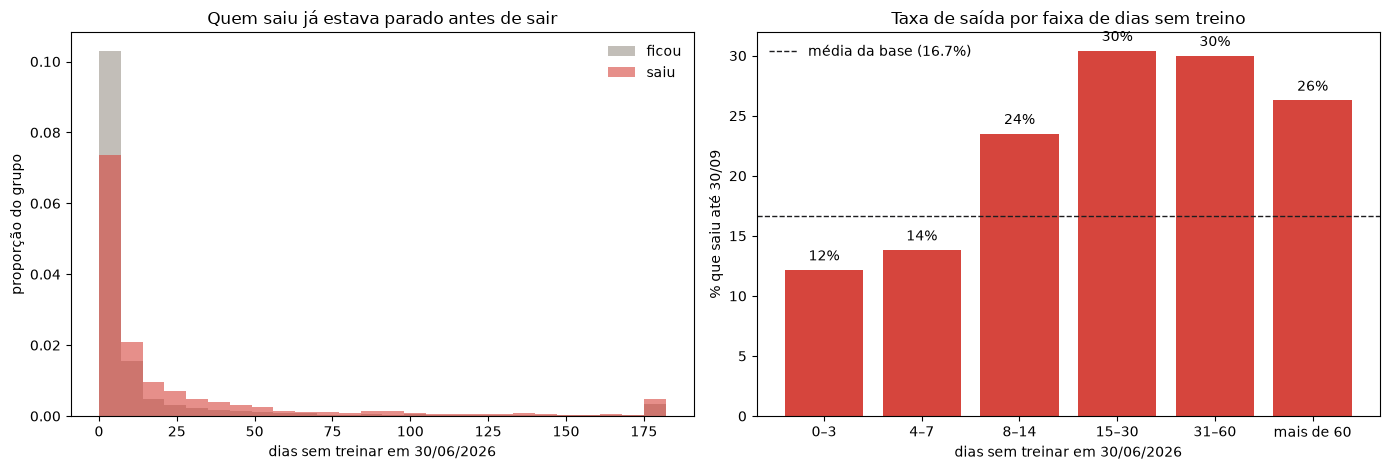

In [22]:
top = "dias_sem_treino"
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
bins = np.arange(0, 185, 7)
for g, cor, nome in [(0, COR_FICOU, "ficou"), (1, COR_SAIU, "saiu")]:
    axs[0].hist(tab.loc[tab["saiu"] == g, top], bins=bins, density=True, alpha=.6, color=cor, label=nome)
axs[0].set_xlabel("dias sem treinar em 30/06/2026"); axs[0].set_ylabel("proporção do grupo")
axs[0].set_title("Quem saiu já estava parado antes de sair"); axs[0].legend(frameon=False)

t = tab.groupby("faixa_dias_sem_treino", observed=True)["saiu"].mean() * 100
axs[1].bar(t.index.astype(str), t.values, color=COR_SAIU)
axs[1].axhline(tab["saiu"].mean() * 100, color="#1d1d1f", ls="--", lw=1, label=f"média da base ({tab['saiu'].mean():.1%})")
for i, v in enumerate(t.values):
    axs[1].text(i, v + .8, f"{v:.0f}%", ha="center", fontsize=10)
axs[1].set_xlabel("dias sem treinar em 30/06/2026"); axs[1].set_ylabel("% que saiu até 30/09")
axs[1].set_title("Taxa de saída por faixa de dias sem treino"); axs[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "02_dias_sem_treino.png", dpi=130, bbox_inches="tight"); plt.show()

## Passo 6 · Testar uma terceira variável: o plano

A taxa por plano parece dizer que o anual sai muito menos (10,9% contra 24,7%). Antes de acreditar, fizemos a pergunta do roteiro: **esse grupo podia sair no período?** O assinante anual só deixa de pagar na renovação. Quem renova em março não tinha como sair entre julho e setembro. Calculamos a próxima renovação de cada anual e separamos quem renovava dentro da janela.

In [23]:
# O anual só pode sair na renovação. Próxima renovação prevista = último pagamento anual antes de 01/07 + 1 ano.
pagos_anual = antes[antes["evento"].isin(["assinatura_iniciada", "renovacao"]) & (antes["plano"] == "anual")]
prox_renov = (pagos_anual.groupby("user_id")["data_hora_brt"].max() + pd.DateOffset(years=1)).rename("proxima_renovacao")
tab = tab.join(prox_renov)
tab["podia_sair"] = (tab["plano_30jun"] == "mensal") | tab["proxima_renovacao"].between(INICIO_JANELA, FIM_JANELA, inclusive="left")

expo = (tab.groupby(["plano_30jun", "podia_sair"])["saiu"].agg(assinantes="size", saíram="sum", taxa_saida="mean"))
print("Anuais sem pagamento anual no log (assinaram antes de 07/2024 e não renovaram desde):",
      ((tab["plano_30jun"] == "anual") & tab["proxima_renovacao"].isna()).sum())
expo

Anuais sem pagamento anual no log (assinaram antes de 07/2024 e não renovaram desde): 0


assinantes  saíram  taxa_saida
plano_30jun podia_sair                                
anual       False             6278       1        0.00
            True              1934     897        0.46
mensal      True              5847    1445        0.25

**Achado 4, o mais importante deste passo.** Entre os anuais que **podiam** sair, **46% saíram**, contra 25% dos mensais. A taxa baixa do anual vinha de três quartos dos anuais simplesmente não renovarem no trimestre. Comparar planos sem olhar a exposição levaria à conclusão oposta.

A trilha de negócios destaca o **tempo de casa**. Na correlação geral ele quase não aparece (−0,04), mas é porque ali os dois planos estão misturados. Abrimos por plano, só entre quem podia sair:

In [24]:
tab["faixa_tempo_casa"] = pd.cut(tab["tempo_casa_dias"], [-1, 60, 180, 365, 730, 99999],
                                 labels=["até 2 meses", "2–6 meses", "6–12 meses", "1–2 anos", "mais de 2 anos"])
expostos = tab[tab["podia_sair"]]
casa = (expostos.groupby(["faixa_tempo_casa", "plano_30jun"], observed=True)["saiu"]
        .agg(assinantes="size", taxa_saida="mean").unstack(1))
casa

assinantes          taxa_saida       
plano_30jun           anual   mensal      anual mensal
faixa_tempo_casa                                      
até 2 meses             NaN 1,090.00        NaN   0.33
2–6 meses               NaN 1,800.00        NaN   0.30
6–12 meses         1,150.00 1,245.00       0.52   0.22
1–2 anos             495.00 1,230.00       0.42   0.18
mais de 2 anos       289.00   482.00       0.33   0.10

No **mensal**, a saída cai de 33% (até 2 meses de casa) para 10% (mais de 2 anos). No **anual**, a primeira renovação é a mais crítica: 52% de saída entre quem completava o primeiro ano, contra 33% depois de 2 anos. O tempo de casa importa, e de forma diferente em cada plano.

**Limite desta leitura:** a base é quem pagava em 30/06. Quem assinou em julho e saiu até setembro (171 pessoas) não entra, então a saída dos primeiros meses aqui é, se algo, **subestimada**.

Agora, a relação entre dias sem treino e saída, aberta por plano, **só entre quem podia sair**:

In [25]:
expostos = tab[tab["podia_sair"]]
terc = (expostos.groupby(["plano_30jun", "faixa_dias_sem_treino"], observed=True)["saiu"]
        .agg(assinantes="size", taxa_saida="mean").unstack(0))
terc

assinantes        taxa_saida       
plano_30jun                anual mensal      anual mensal
faixa_dias_sem_treino                                    
0–3                          723   3941       0.16   0.21
4–7                          222   1058       0.31   0.23
8–14                         199    571       0.55   0.36
15–30                        188    229       0.82   0.55
31–60                        214     42       0.86   0.76
mais de 60                   388      6       0.69   0.67

A relação **se mantém nos dois planos**: quanto mais dias parado, maior a saída. No anual, a diferença é ainda maior (16% para quem treinou nos últimos 3 dias, mais de 80% para quem estava parado havia 15 a 60 dias). Para comparação, a mesma tabela **sem** o filtro de exposição subestima a saída do anual em todas as faixas:

In [26]:
terc_toda = (tab.groupby(["plano_30jun", "faixa_dias_sem_treino"], observed=True)["saiu"]
        .agg(assinantes="size", taxa_saida="mean").unstack(0))
terc_toda

assinantes        taxa_saida       
plano_30jun                anual mensal      anual mensal
faixa_dias_sem_treino                                    
0–3                         3846   3941       0.03   0.21
4–7                         1192   1058       0.06   0.23
8–14                         773    571       0.14   0.36
15–30                        698    229       0.22   0.55
31–60                        678     42       0.27   0.76
mais de 60                  1025      6       0.26   0.67

E a renovação desligada, entre quem podia sair:

In [27]:
terc2 = (expostos.groupby(["plano_30jun", "renovacao_desligada"])["saiu"]
         .agg(assinantes="size", taxa_saida="mean").unstack(0))
terc2

assinantes        taxa_saida       
plano_30jun              anual mensal      anual mensal
renovacao_desligada                                    
False                     1197   5558       0.17   0.21
True                       737    289       0.94   0.99

Quem já tinha desligado a renovação até 30/06 saiu quase sempre (94% no anual, 99% no mensal). Isso confirma que a variável é a saída anunciada, não uma causa a investigar.

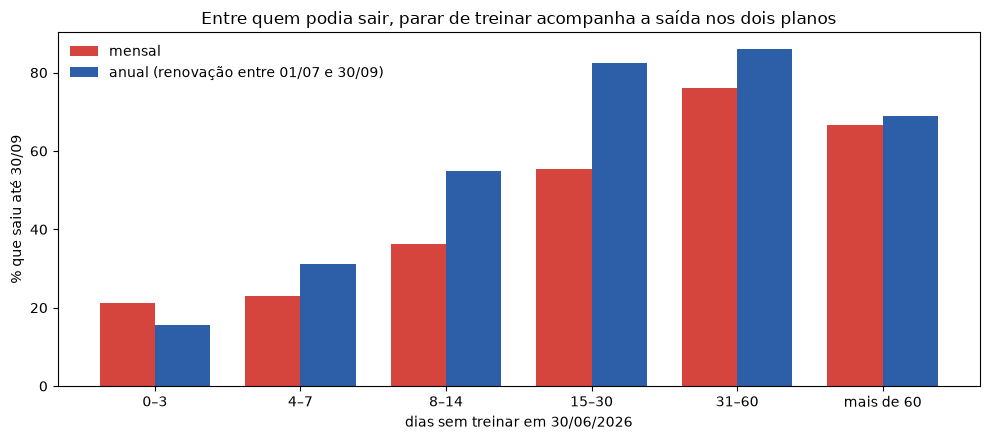

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
faixas = tab["faixa_dias_sem_treino"].cat.categories
x = np.arange(len(faixas)); w = .38
for i, (plano, cor) in enumerate([("mensal", COR_SAIU), ("anual", "#2d5fa8")]):
    t = expostos[expostos["plano_30jun"] == plano].groupby("faixa_dias_sem_treino", observed=False)["saiu"].mean().reindex(faixas) * 100
    ax.bar(x + (i - .5) * w, t.values, w, color=cor, label=plano + (" (renovação entre 01/07 e 30/09)" if plano == "anual" else ""))
ax.set_xticks(x, faixas); ax.set_xlabel("dias sem treinar em 30/06/2026"); ax.set_ylabel("% que saiu até 30/09")
ax.set_title("Entre quem podia sair, parar de treinar acompanha a saída nos dois planos"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "03_terceira_variavel_plano.png", dpi=130, bbox_inches="tight"); plt.show()

O roteiro pede ver **quando** a renovação foi desligada em relação ao uso medido (abril a junho):

In [29]:
desl = antes[antes["evento"].isin({"renovacao_automatica_desligada", "cancelamento_web"})]
desl_saiu = desl[desl["user_id"].isin(saidas_janela)].groupby("user_id")["data_hora_brt"].max()
quando = pd.cut(desl_saiu, [pd.Timestamp("2000-01-01"), INICIO_USO, INICIO_JANELA],
                labels=["antes de abril", "entre abril e junho"]).value_counts()
print("Entre os que saíram, último desligamento da renovação antes de 01/07:"); print(quando.to_string())
print("Saíram sem desligamento registrado antes de 01/07:", len(saidas_janela & set(tab.index)) - len(desl_saiu))

Entre os que saíram, último desligamento da renovação antes de 01/07:
data_hora_brt
entre abril e junho    527
antes de abril         496
Saíram sem desligamento registrado antes de 01/07: 1320


Dos que saíram, 1.023 já tinham desligado a renovação antes de 01/07: metade antes de abril, metade entre abril e junho. Os outros **1.320 (56%) saíram sem nenhum aviso antes da janela**. É nesse grupo que um sinal de uso, como dias sem treino, pode antecipar a saída.

## Passo 7 · Conferir três assinantes à mão

Sorteamos três assinantes (semente fixa, 42) e abrimos o histórico de cada um, para ver se o rótulo e as variáveis batem com os eventos.

In [30]:
amostra = tab.sample(3, random_state=42).index.tolist()
for u in amostra:
    print(f"\n=== {u}  saiu={tab.loc[u, 'saiu']}  plano={tab.loc[u, 'plano_30jun']}  dias_sem_treino={tab.loc[u, 'dias_sem_treino']}")
    print(eventos.loc[eventos["user_id"] == u, ["data_hora_brt", "evento", "plano", "canal_cobranca"]].tail(6).to_string(index=False))
    ult = ativ.loc[(ativ["user_id"] == u) & (ativ["inicio_brt"] < INICIO_JANELA), "inicio_brt"].max()
    print("último treino antes de 01/07:", ult)


=== u_c9f7c0c9  saiu=0  plano=anual  dias_sem_treino=5.0
      data_hora_brt    evento plano canal_cobranca
2024-10-07 19:43:25 renovacao anual      app_store
2025-10-07 16:42:44 renovacao anual      app_store
último treino antes de 01/07: 2026-06-25 07:18:00

=== u_7747cbc4  saiu=1  plano=mensal  dias_sem_treino=0.0
      data_hora_brt                         evento  plano canal_cobranca
2026-05-19 17:14:30                 trial_iniciado    NaN    google_play
2026-05-26 06:10:20            assinatura_iniciada mensal    google_play
2026-06-25 12:00:46                      renovacao mensal    google_play
2026-07-12 08:56:10 renovacao_automatica_desligada mensal    google_play
2026-07-25 21:26:36            assinatura_expirada mensal    google_play
último treino antes de 01/07: 2026-06-30 20:26:00

=== u_e4bad048  saiu=0  plano=anual  dias_sem_treino=28.0
      data_hora_brt              evento plano canal_cobranca
2026-01-29 13:41:15      trial_iniciado   NaN        web_pix
2026-02-05 

Os três conferem. `u_7747cbc4` pagava em 30/06, desligou a renovação em 12/07 e expirou em 25/07: **saiu**, e o desligamento aconteceu depois de 30/06, então não entra como variável. Os dois anuais não tinham renovação nem expiração na janela: **ficaram**. Os dias sem treino batem com a data do último treino.

## O que concluímos: três frases

1. **O que o dado diz.** Quem saiu entre julho e setembro já treinava menos antes de sair: em 30/06, a mediana era de 6 dias sem treinar, contra 2 de quem ficou. A partir de 8 dias parado, a taxa de saída dobra (de 12% para 23% ou mais), e essa relação se mantém nos dois planos.
2. **O que o dado não diz.** Não diz que parar de treinar *causa* a saída: o cruzamento aponta um suspeito, não prova causa. Também não diz que o plano anual retém mais. Entre os anuais que renovavam no trimestre, 46% saíram, contra 25% dos mensais. A taxa menor do anual vinha de ele não poder sair fora da renovação.
3. **A próxima pergunta.** Entre os 56% que saíram sem desligar a renovação antes, quantos dias sem treino já bastam para antecipar a saída a tempo de agir? E isso muda por segmento? É o que levamos para a segmentação e para o modelo de risco.

**Limites que declaramos:** a base de 30/06 não inclui quem assinou e saiu dentro do trimestre; o uso foi medido em três meses; e uma correlação de Spearman fraca pode esconder um efeito que muda de direção entre planos, como aconteceu com o tempo de casa.

**O que fica para a segmentação:** `dados/processados/assinantes_30jun.csv`, com uma linha por assinante e todas as variáveis acima. As decisões deste notebook estão no `decisoes.md`.